# СИЛАНТ · 03. Внешние факторы: датасет и отбор

**Задача:** собрать квартальные ряды 2022–2026 по внешним факторам с источниками, добавить прогнозы ЦБ и Минэкономразвития на 2026–2028 и отобрать 2–3 фактора для модели. Отбор идёт **от экономической логики и ожидаемого лага**, а корреляции служат только проверкой на противоречие: на 13 точках корреляция ничего не доказывает.

**Входы:**
- `data/external/raw/` — выгрузки Банка России (ключевая ставка, курс, кредиты юрлицам, мониторинг предприятий, платёжный баланс); обновляются скриптом `src/fetch_external.py`;
- `data/external/manual/` — показатели Росстата (по публикациям Интерфакса/РБК/Финмаркета со ссылками: сайт Росстата из среды выгрузки недоступен), прогнозы ЦБ и Минэкономразвития/опроса аналитиков, контекстные данные (лизинг, склады).

**Выходы:** `data/processed/macro_quarterly_long.csv` (каждое значение с источником, ссылкой и датой выгрузки), `macro_quarterly_wide.csv`, `macro_forecasts.csv`, `factors_selected.csv`.

---
**Место в пайплайне:** шаг 3 из 6. Предыдущий: 02 — тренды и сезонность. Следующий: 04 — прогноз на 4 квартала. Запуск всех шагов: `python update.py`.

**Вход:** `data/external/raw/*` (ряды Банка России), `data/external/manual/*` (Росстат, прогнозы), `data/processed/market_long.csv`.

**Выход:** `data/processed/macro_quarterly_long.csv`, `macro_quarterly_wide.csv`, `macro_forecasts.csv`, `factor_lag_check.csv`, `factor_cny_vs_usd_check.csv`, `factors_selected.csv`; графики `20–23_*.png`.

**Содержание:** 0. Настройка · 1. Что собрано · 2. Отбор факторов: логика → лаг → данные → прогнозы · 3. Проверка лагов на данных (не отбор!) · 4. Прогнозы ЦБ, Минэкономразвития и аналитиков на 2026–2028 (входы для сценариев) · 5. Итог отбора · 6. Выводы · Источники

## 0. Настройка
Импорт библиотек, пути (относительно корня проекта), параметры и фиксированный seed для случайных чисел. Общие функции вынесены в модули `src/`, чтобы ноутбук содержал только логику анализа.

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from silant_data import load_market
from silant_ts import build_series
from silant_macro import build_macro, RETRIEVED

SEED = 42
rng = np.random.default_rng(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
OUT = ROOT / "data/processed"
FIG = ROOT / "reports/figures"
COL = {"ДВС": "#eb6834", "Электро": "#2a78d6", "Рынок": "#52514e"}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8a8984",
        "font.size": 10,
        "axes.titleweight": "bold",
        "axes.titlesize": 10.5,
        "lines.linewidth": 2,
    }
)


def qlab(p):
    return f"{('I', 'II', 'III', 'IV')[p.quarter - 1]} кв. {p.year}"


def qaxis(ax, idx, step=2):
    xs = idx.to_timestamp()
    ax.set_xticks(xs[::step], [qlab(p) for p in idx][::step], rotation=45)


SOURCE_NOTE = (
    "Источники: Банк России, Росстат (по публикациям Интерфакса), данные заказчика; расчёты автора."
)
UNITS = {}


def save(fig, name):
    # подпись оси Y (единицы) там, где её нет, и источник данных под рисунком
    unit = UNITS.get(name)
    if unit:
        for ax in fig.axes:
            if not ax.get_ylabel() and ax.get_label() != "<colorbar>":
                ax.set_ylabel(unit)
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.01, bottom - 0.02, SOURCE_NOTE, fontsize=8, color="#555555", ha="left", va="top")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


long_m, wide = build_macro(ROOT)
long_m.to_csv(OUT / "macro_quarterly_long.csv", index=False, encoding="utf-8-sig")
w = wide.copy()
w.index = w.index.astype(str)
w.to_csv(OUT / "macro_quarterly_wide.csv", encoding="utf-8-sig")
fc = pd.read_csv(ROOT / "data/external/manual/macro_forecasts.csv")
fc.to_csv(OUT / "macro_forecasts.csv", index=False, encoding="utf-8-sig")
ctx = pd.read_csv(ROOT / "data/external/manual/context_not_quarterly.csv")

S = build_series(load_market(ROOT / "data/raw/silant_forklift_market.xlsx")[0])
SF = pd.read_csv(OUT / "seasonal_factors.csv", index_col=0)
Y = pd.DataFrame(
    {
        c: np.log(S[c] / SF.loc[c].to_numpy()[S.index.quarter - 1])
        for c in ["Рынок", "ДВС", "Электро"]
    }
)
print(
    "Снимок внешних данных от",
    RETRIEVED,
    "| рядов:",
    long_m.indicator.nunique(),
    "| значений:",
    long_m.value.notna().sum(),
)

Снимок внешних данных от 2026-09-25 | рядов: 21 | значений: 423


## 1. Что собрано

In [2]:
cov = (
    long_m.dropna(subset=["value"])
    .groupby("indicator")
    .agg(
        первый=("quarter", "min"),
        последний=("quarter", "max"),
        n=("value", "size"),
        ед=("unit", "first"),
        источник=("source_org", "first"),
        через=("publisher", "first"),
    )
)
cov

,первый,последний,n,ед,источник,через
indicator,,,,,,
cny_rub_avg,2022Q1,2026Q3,19,руб./юань,Банк России,Банк России
credit_debt_end_bln,2021Q1,2026Q2,22,млрд руб.,Банк России,Банк России
credit_debt_yoy,2022Q1,2026Q2,18,"% г/г, номинал",Банк России,Банк России
credit_new_bln,2021Q1,2026Q2,22,млрд руб.,Банк России,Банк России
credit_new_yoy,2022Q1,2026Q2,18,"% г/г, номинал",Банк России,Банк России
goods_imports_musd,2021Q1,2026Q1,21,млн долл.,Банк России,Банк России
goods_imports_yoy,2022Q1,2026Q1,17,"% г/г, в долл.",Банк России,Банк России
inv_act_econ,2021Q1,2026Q2,22,"пункты (баланс ответов, SA)",Банк России,Банк России
inv_act_industry,2021Q1,2026Q2,22,"пункты (баланс ответов, SA)",Банк России,Банк России


**Что не удалось собрать как квартальный официальный ряд** (записано в `context_not_quarterly.csv`):
| Фактор | Что есть | Почему не квартальный ряд |
|---|---|---|
| Лизинг | Эксперт РА: новый бизнес по полугодиям 2022–2026 (770 → 1490 → 1480 → 813 → 853 млрд руб. за I пол.), доля погрузчиков 2,2 % в I пол. 2026 (+46,7 % г/г) | Публикуется по полугодиям; сегмент «погрузчики» — одна точка. Как квартальный прокси финансирования используем кредиты ЦБ |
| Складское строительство | IBC/NF Group: ввод 2024 > 4,9 млн м², 9 мес. 2025 — 3,46 млн м², I кв. 2026 — 1,7 млн м² (спрос −33 % г/г) | Данные консультантов, методики различаются, квартальный ряд из текстов не восстанавливается |
| Импорт спецтехники | Нет | ФТС не публикует детальную статистику с 2022 г.; открытых данных по ТН ВЭД 8427 нет. Есть только общий импорт товаров (платёжный баланс) |
| Промпроизводство III–IV кв. 2022 | Нет | Росстат недоступен, в найденных публикациях квартальных значений нет |
| Утильсбор на спецтехнику | Повышение ~15–20 % с 1.01.2026 (дилерский блог) | Не НПА; распространение на погрузчики не подтверждено — это гипотеза для проверки |

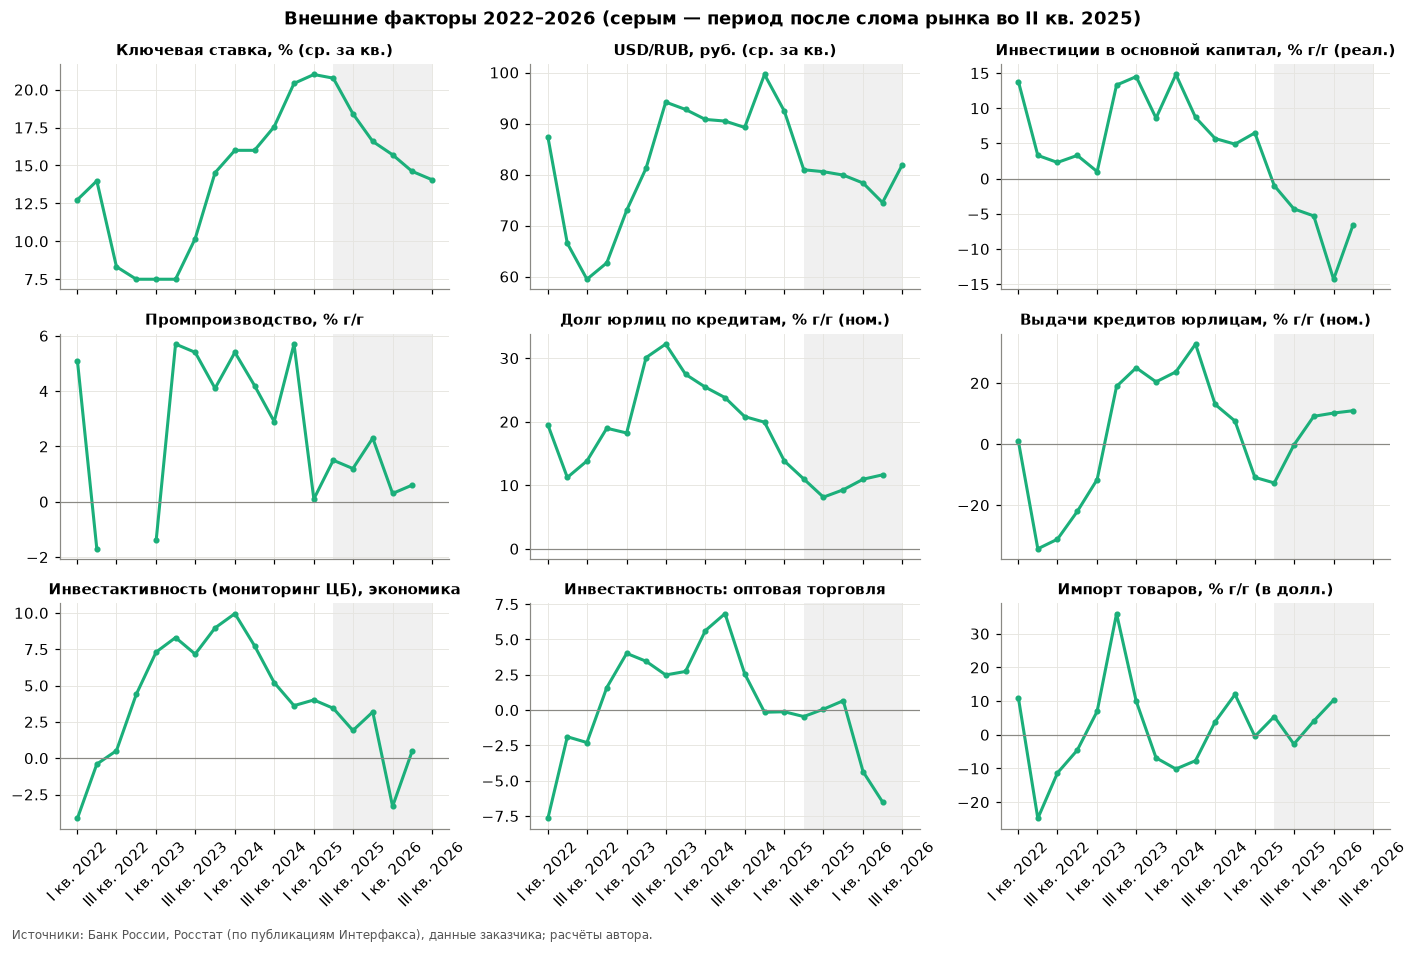

In [3]:
show = [
    ("key_rate_avg", "Ключевая ставка, % (ср. за кв.)"),
    ("usd_rub_avg", "USD/RUB, руб. (ср. за кв.)"),
    ("invest_fc_yoy", "Инвестиции в основной капитал, % г/г (реал.)"),
    ("ipp_yoy", "Промпроизводство, % г/г"),
    ("credit_debt_yoy", "Долг юрлиц по кредитам, % г/г (ном.)"),
    ("credit_new_yoy", "Выдачи кредитов юрлицам, % г/г (ном.)"),
    ("inv_act_econ", "Инвестактивность (мониторинг ЦБ), экономика"),
    ("inv_act_wholesale", "Инвестактивность: оптовая торговля"),
    ("goods_imports_yoy", "Импорт товаров, % г/г (в долл.)"),
]
fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True)
x = wide.index.to_timestamp()
for ax, (c, t) in zip(axes.flat, show):
    ax.plot(x, wide[c].astype(float), color="#1baf7a", marker="o", ms=3)
    ax.axvspan(pd.Period("2025Q2").to_timestamp(), x[-1], color="#8a8984", alpha=0.12, lw=0)
    if c.endswith("yoy") or c.startswith("inv_"):
        ax.axhline(0, color="#8a8984", lw=0.8)
    ax.set_title(t, fontsize=9.5)
    qaxis(ax, wide.index)
fig.suptitle(
    "Внешние факторы 2022–2026 (серым — период после слома рынка во II кв. 2025)", fontweight="bold"
)
fig.tight_layout()
save(fig, "20_macro_panel")

## 2. Отбор факторов: логика → лаг → данные → прогнозы

Критерии (в порядке важности):
1. **Канал влияния на спрос на погрузчики** — понятный механизм и ожидаемый знак.
2. **Лаг из механизма** (а не подбор по данным).
3. **Квартальный официальный ряд** с 2022 года.
4. **Есть официальные прогнозы** на 2026–2028 (ЦБ, Минэкономразвития, опрос аналитиков) — без них фактор бесполезен для сценариев на 4–8 кварталов.
5. **Не дублирует уже выбранный фактор** (на 13 точках два коррелированных фактора не разделить).

In [4]:
sel = pd.DataFrame(
    [
        [
            "Ключевая ставка",
            "Стоимость лизинга/кредита → отложенные покупки техники; ставка задаёт и спрос клиентов (стройка, склады, производство)",
            "−",
            "2 кв. (разумный диапазон 1–3): решение о покупке → одобрение лизинга → поставка из Китая",
            "да",
            "ЦБ (диапазоны), опрос ЦБ, Минэкономразвития",
            "ВЫБРАН (основной)",
        ],
        [
            "Инвестиции в основной капитал",
            "Погрузчики — часть инвестиций в оборудование; прямой индикатор спроса со стороны складов, производства, торговли",
            "+",
            "0–1 кв. (совпадающий показатель: закупка техники — это и есть инвестиция)",
            "да (Росстат, через СМИ)",
            "Минэкономразвития (сент. 2026), ЦБ (валовое накопление ОК)",
            "ВЫБРАН (спрос)",
        ],
        [
            "Курс USD/RUB",
            "Почти вся техника импортная или из импортных комплектующих: ослабление рубля → рост цен в рублях → снижение спроса; возможен и обратный эффект (закупки «до подорожания»)",
            "− (с оговоркой)",
            "1–2 кв. (оборот складских запасов у дилеров)",
            "да",
            "опрос ЦБ, Минэкономразвития",
            "ВЫБРАН для сценариев, но не в базовую регрессию",
        ],
        [
            "Мониторинг ЦБ: инвестактивность (опт, транспорт и хранение)",
            "Опросный опережающий индикатор инвестпланов ключевых клиентов складской техники",
            "+",
            "0–1 кв.",
            "да",
            "нет",
            "индикатор для мониторинга/наукаста, не сценарный фактор",
        ],
        [
            "Кредиты юрлицам",
            "Канал ставки; номинальный, растёт с инфляцией; зависит от ставки",
            "+",
            "0–1 кв.",
            "да",
            "ЦБ (требования к организациям, % г/г)",
            "не выбран: дублирует ставку",
        ],
        [
            "Промпроизводство",
            "Спрос промышленных клиентов, но ИПП колеблется в пределах ±6 % и не объясняет падение рынка на треть",
            "+",
            "0–2 кв.",
            "частично (нет III–IV кв. 2022)",
            "Минэкономразвития (2026–2027)",
            "не выбран: мала вариация, слабая связь",
        ],
        [
            "Импорт товаров (платёжный баланс)",
            "Общий импорт, а не импорт погрузчиков",
            "±",
            "—",
            "да",
            "ЦБ",
            "не выбран: не специфичен",
        ],
        [
            "Складское строительство",
            "Ввод складов → спрос на складскую (в основном электро) технику",
            "+",
            "0–2 кв.",
            "нет (консультанты, годовые)",
            "NF Group (годовой)",
            "не выбран: нет квартального ряда; качественно — в сценарии",
        ],
        [
            "Лизинг",
            "Главный канал финансирования, но это передаточное звено ставки",
            "+",
            "0–1 кв.",
            "нет (полугодия)",
            "нет",
            "не выбран: частота; ставка покрывает канал",
        ],
    ],
    columns=[
        "фактор",
        "механизм",
        "знак",
        "ожидаемый лаг",
        "квартальный ряд",
        "прогнозы 2026–2028",
        "решение",
    ],
)
sel.set_index("фактор")

,механизм,знак,ожидаемый лаг,квартальный ряд,прогнозы 2026–2028,решение
фактор,,,,,,
Ключевая ставка,Стоимость лизинга/кредита → отложенные покупки техники; ставка задаёт и спрос клиентов...,−,2 кв. (разумный диапазон 1–3): решение о покупке → одобрение лизинга → поставка из Китая,да,"ЦБ (диапазоны), опрос ЦБ, Минэкономразвития",ВЫБРАН (основной)
Инвестиции в основной капитал,Погрузчики — часть инвестиций в оборудование; прямой индикатор спроса со стороны склад...,+,0–1 кв. (совпадающий показатель: закупка техники — это и есть инвестиция),"да (Росстат, через СМИ)","Минэкономразвития (сент. 2026), ЦБ (валовое накопление ОК)",ВЫБРАН (спрос)
Курс USD/RUB,Почти вся техника импортная или из импортных комплектующих: ослабление рубля → рост це...,− (с оговоркой),1–2 кв. (оборот складских запасов у дилеров),да,"опрос ЦБ, Минэкономразвития","ВЫБРАН для сценариев, но не в базовую регрессию"
"Мониторинг ЦБ: инвестактивность (опт, транспорт и хранение)",Опросный опережающий индикатор инвестпланов ключевых клиентов складской техники,+,0–1 кв.,да,нет,"индикатор для мониторинга/наукаста, не сценарный фактор"
Кредиты юрлицам,"Канал ставки; номинальный, растёт с инфляцией; зависит от ставки",+,0–1 кв.,да,"ЦБ (требования к организациям, % г/г)",не выбран: дублирует ставку
Промпроизводство,"Спрос промышленных клиентов, но ИПП колеблется в пределах ±6 % и не объясняет падение ...",+,0–2 кв.,частично (нет III–IV кв. 2022),Минэкономразвития (2026–2027),"не выбран: мала вариация, слабая связь"
Импорт товаров (платёжный баланс),"Общий импорт, а не импорт погрузчиков",±,—,да,ЦБ,не выбран: не специфичен
Складское строительство,Ввод складов → спрос на складскую (в основном электро) технику,+,0–2 кв.,"нет (консультанты, годовые)",NF Group (годовой),не выбран: нет квартального ряда; качественно — в сценарии
Лизинг,"Главный канал финансирования, но это передаточное звено ставки",+,0–1 кв.,нет (полугодия),нет,не выбран: частота; ставка покрывает канал


## 3. Проверка лагов на данных (не отбор!)
Считаем корреляцию сезонно скорректированного логарифма продаж с фактором при лагах 0–4 квартала. Чтобы понять, что на 13 точках вообще считается «сильной» связью, строим **нулевое распределение**: 5 000 раз генерируем случайный ряд AR(1) с той же инерционностью, что у фактора, и берём **лучшую** по модулю корреляцию из пяти лагов — так же, как её выбирал бы человек, перебирающий лаги. Если реальная корреляция не выходит за 95-й перцентиль этого распределения, она неотличима от совпадения двух трендов.

In [5]:
def ar1_phi(s):
    s = s.dropna().to_numpy()
    s = s - s.mean()
    return float(np.clip((s[1:] @ s[:-1]) / (s[:-1] @ s[:-1]), -0.95, 0.98))


def lag_corr(f, y, lags=range(5)):
    return pd.Series({l: f.shift(l).reindex(y.index).corr(y) for l in lags})


def null_max_abs(f, y, n_sim=5000, lags=range(5)):
    phi = ar1_phi(f)
    n = len(f)
    y = y[y.index.isin(f.index)]  # рынок может быть длиннее фактора (новые кварталы раньше данных Росстата)
    yv = y.to_numpy()
    out = np.empty(n_sim)
    pos = np.array([f.index.get_loc(q) for q in y.index])
    for i in range(n_sim):
        e = rng.normal(size=n + 50)
        z = np.zeros_like(e)
        for t in range(1, len(e)):
            z[t] = phi * z[t - 1] + e[t]
        z = z[50:]
        out[i] = max(abs(np.corrcoef(z[pos - l], yv)[0, 1]) for l in lags)
    return np.quantile(out, 0.95), phi


cand = {
    "key_rate_avg": ("Ключевая ставка", -1),
    "invest_fc_yoy": ("Инвестиции в основной капитал, г/г", +1),
    "usd_rub_avg": ("USD/RUB", -1),
    "inv_act_transport_storage": ("Инвестактивность: транспорт и хранение", +1),
    "credit_debt_yoy": ("Долг юрлиц, г/г", +1),
    "ipp_yoy": ("Промпроизводство, г/г", +1),
}
F = wide.astype(float).copy()
F["usd_rub_avg"] = np.log(F["usd_rub_avg"])
rows, heat = [], {}
for c, (name, sign) in cand.items():
    f = F[c].interpolate(limit_area="inside")
    f = f[f.index <= Y.index.max()].dropna()
    for tgt in ["Рынок", "ДВС", "Электро"]:
        lc = lag_corr(f, Y[tgt])
        heat[(name, tgt)] = lc
        thr, phi = null_max_abs(f, Y[tgt], n_sim=2000 if tgt != "Рынок" else 5000)
        best = lc.abs().idxmax()
        rows.append(
            {
                "фактор": name,
                "ряд": tgt,
                "ожид. знак": "+" if sign > 0 else "−",
                "лучший лаг": best,
                "r при лучшем лаге": round(lc[best], 2),
                "знак совпал": np.sign(lc[best]) == sign,
                "порог 95 % (случайный AR(1))": round(thr, 2),
                "AR(1) φ": round(phi, 2),
                "выше порога": abs(lc[best]) > thr,
            }
        )
chk = pd.DataFrame(rows)
chk.to_csv(OUT / "factor_lag_check.csv", index=False, encoding="utf-8-sig")
chk

,фактор,ряд,ожид. знак,лучший лаг,r при лучшем лаге,знак совпал,порог 95 % (случайный AR(1)),AR(1) φ,выше порога
0,Ключевая ставка,Рынок,−,3,-0.77,True,0.87,0.88,False
1,Ключевая ставка,ДВС,−,2,-0.80,True,0.89,0.88,False
2,Ключевая ставка,Электро,−,3,-0.52,True,0.66,0.88,False
3,"Инвестиции в основной капитал, г/г",Рынок,+,0,0.77,True,0.86,0.78,False
4,"Инвестиции в основной капитал, г/г",ДВС,+,0,0.68,True,0.88,0.78,False
5,"Инвестиции в основной капитал, г/г",Электро,+,0,0.63,True,0.68,0.78,False
6,USD/RUB,Рынок,−,4,-0.57,True,0.85,0.74,False
7,USD/RUB,ДВС,−,3,-0.53,True,0.88,0.74,False
8,USD/RUB,Электро,−,0,0.77,False,0.67,0.74,True
9,Инвестактивность: транспорт и хранение,Рынок,+,1,0.72,True,0.82,0.56,False


Тепловая карта корреляций «фактор × лаг» для рынка, ДВС и электро: знак и сила связи при разных задержках. Для сравнения приведён порог, который даёт случайный инерционный ряд.

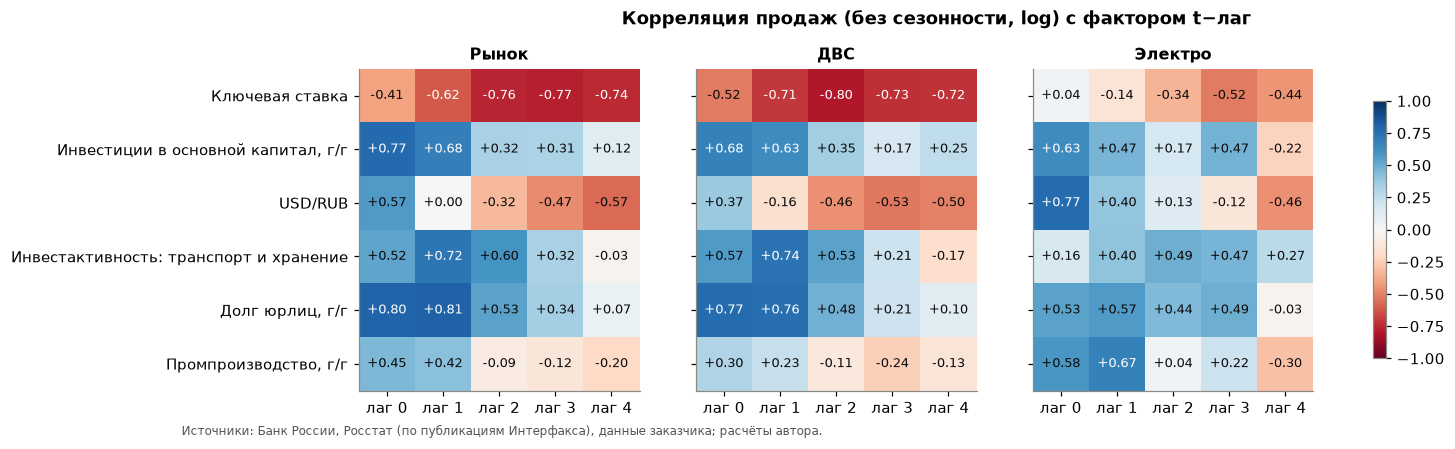

In [6]:
H = pd.DataFrame(heat).T
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, tgt in zip(axes, ["Рынок", "ДВС", "Электро"]):
    h = H.xs(tgt, level=1)
    im = ax.imshow(h.values, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(5), [f"лаг {l}" for l in range(5)])
    ax.set_title(tgt)
    ax.grid(False)
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            v = h.values[i, j]
            ax.text(
                j,
                i,
                f"{v:+.2f}",
                ha="center",
                va="center",
                fontsize=8.5,
                color="white" if abs(v) > 0.6 else "#0b0b0b",
            )
axes[0].set_yticks(range(len(H.xs("Рынок", level=1))), H.xs("Рынок", level=1).index)
fig.colorbar(im, ax=axes, shrink=0.8)
fig.suptitle("Корреляция продаж (без сезонности, log) с фактором t−лаг", fontweight="bold", y=1.02)
save(fig, "21_lag_heatmap")

### 3.1 Ставка и рынок на одной шкале времени

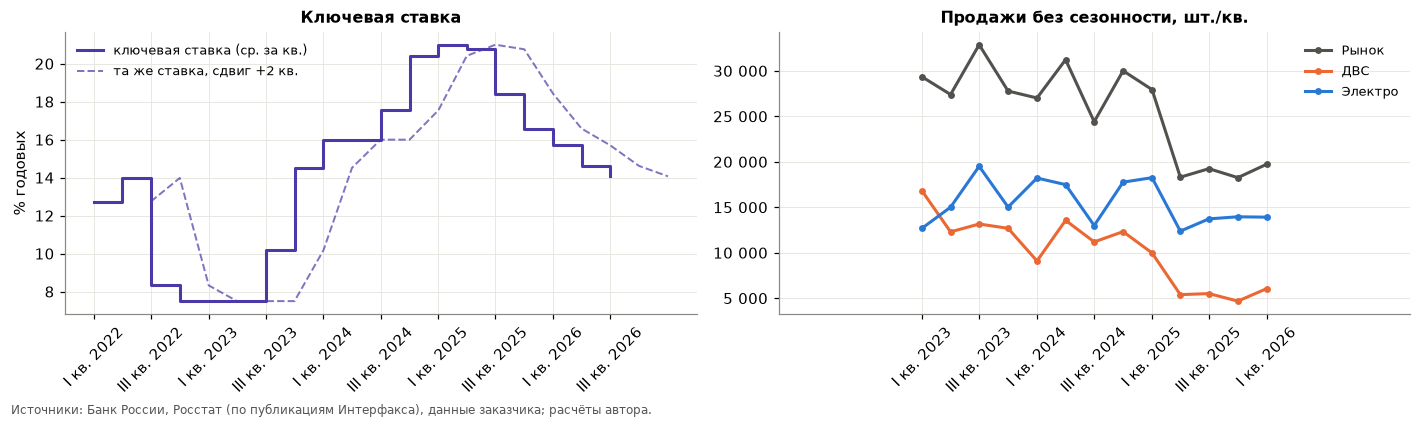

In [7]:
kr = wide["key_rate_avg"].astype(float)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
x = kr.index.to_timestamp()
ax[0].step(x, kr, where="post", color="#4a3aa7", label="ключевая ставка (ср. за кв.)")
ax[0].plot(
    (kr.index + 2).to_timestamp(),
    kr,
    color="#4a3aa7",
    ls="--",
    lw=1.3,
    alpha=0.7,
    label="та же ставка, сдвиг +2 кв.",
)
ax[0].set_ylabel("% годовых")
ax[0].legend(frameon=False, fontsize=8.5, loc="upper left")
ax[0].set_title("Ключевая ставка")
qaxis(ax[0], pd.period_range("2022Q1", "2026Q4", freq="Q"))
for c in ["Рынок", "ДВС", "Электро"]:
    ax[1].plot(Y.index.to_timestamp(), np.exp(Y[c]), color=COL[c], marker="o", ms=3.5, label=c)
ax[1].yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax[1].set_title("Продажи без сезонности, шт./кв.")
ax[1].legend(frameon=False, fontsize=8.5)
qaxis(ax[1], Y.index)
ax[1].set_xlim(ax[0].get_xlim())
fig.tight_layout()
save(fig, "22_rate_vs_market")

### 3.2 Не дублируют ли выбранные факторы друг друга

In [8]:
Z = pd.DataFrame(
    {
        "ставка (лаг 2)": F["key_rate_avg"].shift(2),
        "инвестиции г/г (лаг 0)": F["invest_fc_yoy"],
        "инвестиции г/г (лаг 1)": F["invest_fc_yoy"].shift(1),
        "log USD/RUB (лаг 1)": F["usd_rub_avg"].shift(1),
        "инвестактивность транспорт/хранение (лаг 1)": F["inv_act_transport_storage"].shift(1),
    }
).reindex(Y.index)
Z.corr().round(2)

,ставка (лаг 2),инвестиции г/г (лаг 0),инвестиции г/г (лаг 1),log USD/RUB (лаг 1),инвестактивность транспорт/хранение (лаг 1)
ставка (лаг 2),1.00,-0.72,-0.52,0.30,-0.66
инвестиции г/г (лаг 0),-0.72,1.00,0.74,0.23,0.60
инвестиции г/г (лаг 1),-0.52,0.74,1.00,0.45,0.41
log USD/RUB (лаг 1),0.30,0.23,0.45,1.00,-0.10
инвестактивность транспорт/хранение (лаг 1),-0.66,0.60,0.41,-0.10,1.00


### 3.3 Юань вместо доллара: проверка гипотезы
Если основная часть импортной техники поставляется из Китая, для цены импорта логичнее курс **CNY/RUB**, а не USD/RUB. Структуру импорта погрузчиков по странам подтвердить нельзя: детальная статистика ФТС закрыта — это допущение. Гипотеза: курс доллара не прошёл проверку на знак, потому что выбрана «не та» валюта. Проверяем тем же методом, что и в разделе 3 (отдельный seed, чтобы не менять прежние результаты).

In [9]:
cny = np.log(F["cny_rub_avg"].astype(float))
fx2 = pd.DataFrame(
    {"USD/RUB": wide["usd_rub_avg"].astype(float), "CNY/RUB": wide["cny_rub_avg"].astype(float)}
).dropna()
fx2["кросс-курс USD/CNY"] = fx2["USD/RUB"] / fx2["CNY/RUB"]
d = np.log(fx2[["USD/RUB", "CNY/RUB"]]).diff().dropna()
print("Корреляция квартальных изменений log USD/RUB и log CNY/RUB:", round(d.corr().iloc[0, 1], 3))
print(
    "Кросс-курс USD/CNY в 2023–2026: от",
    round(fx2.loc["2023Q1":, "кросс-курс USD/CNY"].min(), 2),
    "до",
    round(fx2.loc["2023Q1":, "кросс-курс USD/CNY"].max(), 2),
)
rng_cny = np.random.default_rng(SEED + 1)
_rng_main = rng
rng = rng_cny
rows_c = []
for name, ser in [("USD/RUB", F["usd_rub_avg"]), ("CNY/RUB", cny)]:
    f = ser[ser.index <= Y.index.max()].dropna()
    for tgt in ["Рынок", "ДВС", "Электро"]:
        lc = lag_corr(f, Y[tgt])
        thr, phi = null_max_abs(f, Y[tgt], n_sim=3000)
        best = lc.abs().idxmax()
        rows_c.append(
            {
                "курс": name,
                "ряд": tgt,
                **{f"лаг {l}": round(v, 2) for l, v in lc.items()},
                "лучший лаг": best,
                "r": round(lc[best], 2),
                "знак совпал (−)": lc[best] < 0,
                "порог 95 %": round(thr, 2),
                "выше порога": abs(lc[best]) > thr,
            }
        )
rng = _rng_main
cny_chk = pd.DataFrame(rows_c)
cny_chk.to_csv(OUT / "factor_cny_vs_usd_check.csv", index=False, encoding="utf-8-sig")
cny_chk

Корреляция квартальных изменений log USD/RUB и log CNY/RUB: 0.978
Кросс-курс USD/CNY в 2023–2026: от 6.74 до 7.33


,курс,ряд,лаг 0,лаг 1,лаг 2,лаг 3,лаг 4,лучший лаг,r,знак совпал (−),порог 95 %,выше порога
0,USD/RUB,Рынок,0.57,0.00,-0.32,-0.47,-0.57,4,-0.57,True,0.85,False
1,USD/RUB,ДВС,0.37,-0.16,-0.46,-0.53,-0.50,3,-0.53,True,0.87,False
2,USD/RUB,Электро,0.77,0.40,0.13,-0.12,-0.46,0,0.77,False,0.67,True
3,CNY/RUB,Рынок,0.64,0.04,-0.28,-0.44,-0.47,0,0.64,False,0.83,False
4,CNY/RUB,ДВС,0.45,-0.14,-0.42,-0.47,-0.36,3,-0.47,True,0.83,False
5,CNY/RUB,Электро,0.80,0.45,0.14,-0.17,-0.49,0,0.80,False,0.68,True


## 4. Прогнозы ЦБ, Минэкономразвития и аналитиков на 2026–2028 (входы для сценариев)

In [10]:
piv = fc[
    fc.indicator.isin(["key_rate_avg", "invest_fc_yoy", "gfcf_yoy", "usd_rub_avg", "gdp_yoy"])
].copy()
piv["значение"] = np.where(
    piv.point.notna(), piv.point.astype(str), piv.low.astype(str) + "…" + piv.high.astype(str)
)
piv = piv[piv.year >= 2026].pivot_table(
    index=["indicator", "source", "vintage"], columns="year", values="значение", aggfunc="first"
)
piv

year                                                                                 2026       2027     2028 2029
indicator     source                                                vintage                                       
gdp_yoy       Макроэкономический опрос ЦБ (медиана 33 аналитиков)   2026-09-01        0.5        1.2      1.7  NaN
              Минэкономразвития (прогноз СЭР, базовый)              2026-09-24        0.6        1.4      1.9  NaN
              Минэкономразвития (прогноз СЭР, консервативный)       2026-09-24        NaN        0.7      NaN  NaN
              Минэкономразвития (сценарные условия, базовый)        2026-05-12        0.4        NaN      NaN  NaN
              Минэкономразвития (сценарные условия, консервативный) 2026-05-12       -0.5        NaN      NaN  NaN
              ЦБ РФ (среднесрочный прогноз)                         2026-07-24    0.0…1.0    1.5…2.5  1.5…2.5  NaN
gfcf_yoy      ЦБ РФ (среднесрочный прогноз)                         2026-07-24   -1.5…0.5    2.0…4.0  1.5…3.5  NaN
invest_fc_yoy Минэкономразвития (прогноз СЭР, базовый)              2026-09-24       -5.4        0.2      2.5  3.0
              Минэкономразвития (сценарные условия, базовый)        2026-05-12       -1.5        2.0      NaN  NaN
key_rate_avg  Макроэкономический опрос ЦБ (медиана 33 аналитиков)   2026-09-01       14.5       12.4     10.0  8.6
              Минэкономразвития (сценарные условия, базовый)        2026-05-12  14.0…14.5        NaN      NaN  NaN
              ЦБ РФ (среднесрочный прогноз)                         2026-07-24  14.5…14.6  10.5…12.5  8.0…9.0  NaN
usd_rub_avg   Макроэкономический опрос ЦБ (медиана 33 аналитиков)   2026-09-01       79.9       88.8     94.0  NaN
              Минэкономразвития (прогноз СЭР, базовый)              2026-09-24       79.5       87.4      NaN  NaN
              Минэкономразвития (сценарные условия, базовый)        2026-05-12       81.5       87.4      NaN  NaN

Прогнозы ЦБ, Минэка и аналитиков по выбранным факторам на графике.

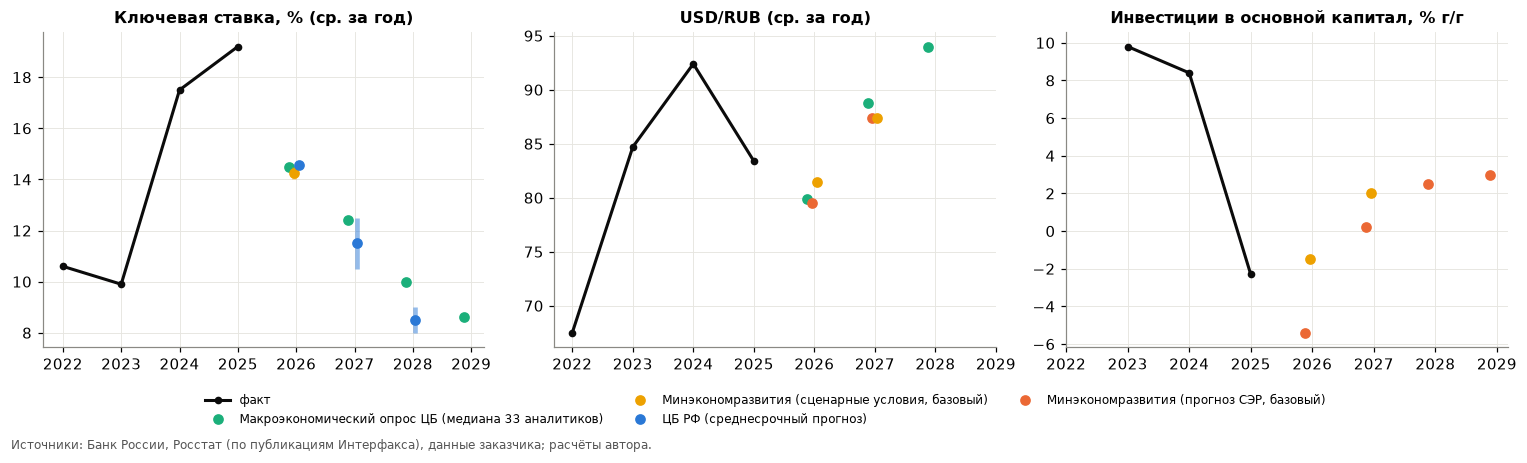

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
hist_y = {
    "key_rate_avg": {2022: 10.6, 2023: 9.9, 2024: 17.5, 2025: 19.2},
    "usd_rub_avg": {2022: 67.5, 2023: 84.7, 2024: 92.4, 2025: 83.4},
    "invest_fc_yoy": {2023: 9.8, 2024: 8.4, 2025: -2.3},
}
titles = {
    "key_rate_avg": "Ключевая ставка, % (ср. за год)",
    "usd_rub_avg": "USD/RUB (ср. за год)",
    "invest_fc_yoy": "Инвестиции в основной капитал, % г/г",
}
srccol = {
    "ЦБ РФ (среднесрочный прогноз)": "#2a78d6",
    "Макроэкономический опрос ЦБ (медиана 33 аналитиков)": "#1baf7a",
    "Минэкономразвития (прогноз СЭР, базовый)": "#eb6834",
    "Минэкономразвития (сценарные условия, базовый)": "#eda100",
}
for ax, ind in zip(axes, titles):
    h = hist_y[ind]
    ax.plot(list(h), list(h.values()), color="#0b0b0b", marker="o", ms=4, label="факт")
    d = fc[(fc.indicator == ind) & (fc.year >= 2026)]
    for (src, g), dx in zip(d.groupby("source"), [-0.12, -0.04, 0.04, 0.12]):
        c = srccol.get(src, "#8a8984")
        pt = g.point.fillna((g.low + g.high) / 2)
        ax.plot(
            g.year + dx,
            pt,
            "o",
            color=c,
            ms=6,
            label=src.split(" (")[0] + (" (" + src.split(" (")[1] if "(" in src else ""),
        )
        rng_ = g.dropna(subset=["low"])
        ax.vlines(rng_.year + dx, rng_.low, rng_.high, color=c, lw=3, alpha=0.5)
    ax.set_title(titles[ind])
    ax.set_xticks([2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029])
hl = {}
for a in axes:
    for h_, l_ in zip(*a.get_legend_handles_labels()):
        hl.setdefault(l_, h_)
fig.legend(
    hl.values(),
    hl.keys(),
    frameon=False,
    fontsize=8,
    ncol=3,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
)
fig.tight_layout()
save(fig, "23_forecasts")

## 5. Итог отбора

In [12]:
fs = pd.DataFrame(
    {
        "key_rate_avg_l2": F["key_rate_avg"].shift(2),
        "invest_fc_yoy_l0": F["invest_fc_yoy"],
        "log_usd_rub_l1": F["usd_rub_avg"].shift(1),
        "inv_act_transport_storage_l1": F["inv_act_transport_storage"].shift(1),
    }
)
fs.index = fs.index.astype(str)
fs.to_csv(OUT / "factors_selected.csv", encoding="utf-8-sig")
fs.round(3).tail(8)

,key_rate_avg_l2,invest_fc_yoy_l0,log_usd_rub_l1,inv_act_transport_storage_l1
quarter,,,,
2024Q4,16.000,4.9,4.491,5.700
2025Q1,17.554,6.5,4.601,5.914
2025Q2,20.413,-1.0,4.526,1.218
2025Q3,21.000,-4.3,4.394,4.680
2025Q4,20.758,-5.3,4.389,3.544
2026Q1,18.413,-14.3,4.381,5.100
2026Q2,16.587,-6.6,4.361,0.386
2026Q3,15.706,NaN,4.311,1.314


### Проверка актуальности выводов
Текст выводов ниже написан по данным до I кв. 2026 г. Если в файле появился новый квартал, эта ячейка выведет предупреждение; таблицы и графики выше при этом пересчитываются автоматически.

In [13]:
from IPython.display import Markdown, display
from silant_data import load_market as _lm
_last = str(_lm(ROOT / 'data/raw/silant_forklift_market.xlsx')[0].quarter.max())
if _last != "2026Q1":
    display(Markdown(f"> ⚠️ **Текст выводов ниже написан по данным до 2026Q1**, а в файле данные уже до **{_last}**. "
                     "Все таблицы и графики выше пересчитаны автоматически; конкретные цифры в тексте могли устареть — "
                     "актуальные значения см. в таблицах выше, в `reports/summary.html` и `reports/silant_forecast.xlsx`."))
else:
    print("Текст выводов соответствует текущим данным (до 2026Q1).")

Текст выводов соответствует текущим данным (до 2026Q1).


## 6. Выводы

### 6.1 Собранный датасет
- **21 квартальный ряд, 423 значения** на 2022–2026 (где данные опубликованы — до II кв. 2026 или III кв. 2026). У каждого значения в `macro_quarterly_long.csv` указаны источник, ссылка и дата выгрузки (25.09.2026).
- **Банк России (первоисточник, выгрузка через официальный API и XML):** ключевая ставка, курсы USD/RUB и CNY/RUB (юань — выгрузка 02.10.2026), кредиты юрлицам (выдачи и задолженность), мониторинг предприятий (инвестактивность), импорт товаров. Средняя ставка сверена с опубликованными ЦБ значениями: 2022 — 10,6; 2023 — 9,9; 2024 — 17,5; 2025 — 19,2; 1.01–26.07.2026 — 15,0 %. Совпадение полное.
- **Росстат (инвестиции в ОК, промпроизводство)** — через публикации Интерфакса, РБК и Финмаркета со ссылками: rosstat.gov.ru, fedstat.ru и economy.gov.ru из среды выгрузки недоступны. Используются последние найденные оценки; поздние пересмотры Росстата (например, 2024 год: 7,4 % → 8,4 %) по кварталам не найдены. Это ограничение.
- **Прогнозы на 2026–2028:** среднесрочный прогноз ЦБ (24.07.2026), Макроэкономический опрос ЦБ (сентябрь 2026, 33 аналитика), прогноз Минэкономразвития (сентябрь 2026, по публикациям СМИ) и весенние сценарные условия (май 2026) — для сравнения вариантов.
- **Не собрано как квартальный ряд:** импорт погрузчиков (ФТС данные закрыла), складское строительство (только оценки консультантов), лизинг (полугодия).

### 6.2 Выбранные факторы
| Фактор | Роль | Лаг | Прогнозы для сценариев |
|---|---|---|---|
| **Ключевая ставка** (ср. за квартал) | Основной драйвер: стоимость финансирования покупки | 2 кв. (чувствительность 1–3) | ЦБ: 14,5–14,6 / 10,5–12,5 / 8–9 % в 2026/27/28; аналитики: 14,5 / 12,4 / 10,0 % |
| **Инвестиции в основной капитал** (реал., г/г) | Спрос клиентов: погрузчик — это инвестиция | 0 кв. | Минэкономразвития: −5,4 / +0,2 / +2,5 %; ЦБ (валовое накопление ОК): −1,5…+0,5 / 2–4 / 1,5–3,5 % |
| **Курс USD/RUB** | Цена импортной техники; только в сценариях | 1–2 кв. | Минэкономразвития: 79,5 / 87,4; аналитики: 79,9 / 88,8 / 94,0 |

Для отслеживания, но не для сценариев: **инвестактивность в транспорте и хранении и в оптовой торговле** (мониторинг ЦБ). Это опережающий опросный индикатор, но официальных прогнозов по нему нет. В I–II кв. 2026 инвестактивность в опте резко ушла в минус (−4,4 и −6,5 п.) — сигнал, что спрос складских клиентов ещё не восстанавливается.

### 6.3 Что показала проверка на данных — и чего она не показала
- **Знаки совпали с ожиданиями, лаги — примерно тоже.** Ставка связана с продажами отрицательно, и сильнее всего при лаге 2–3 квартала (рынок r = −0,77, ДВС −0,80 при лаге 2). Инвестиции связаны положительно при лаге 0 (r = +0,77). На графике видно, что пик ставки (21 % с конца октября 2024), сдвинутый на 2 квартала, приходится ровно на слом рынка во II кв. 2025.
- **Статистически ни одна связь не доказана.** Ни одна корреляция не выходит за порог, который даёт случайный инерционный ряд при выборе лучшего из 5 лагов (порог 0,77–0,89 для рынка и ДВС в зависимости от фактора). На 13 точках два трендовых ряда легко коррелируют случайно. Выбор держится на экономической логике, а данные ей просто не противоречат.
- **Курс рубля не прошёл проверку на знак.** С продажами электро он связан положительно при лаге 0 (r = +0,77, это единственная связь выше порога, но знак обратный). Скорее всего, это совпадение восстановления рынка в 2023 году с ослаблением рубля или закупки «до подорожания». Поэтому курс не входит в базовую модель и используется только как сценарная предпосылка для цен.
- **Замена доллара на юань результат не меняет (раздел 3.3).** Экономически для импорта из Китая правильнее курс CNY/RUB. Но в 2023–2026 гг. рубль к юаню и к доллару двигался почти одинаково: кросс-курс USD/CNY держался в узком коридоре 6,7–7,3, корреляция квартальных изменений 0,98. Поэтому у юаня та же картина: обратный знак у электро при лаге 0 (r = +0,80), у рынка и ДВС — ниже порога случайности. Значит, курс доллара «не подтвердился» не из-за выбора валюты, а потому что на 13 точках эффект курса не отделить от общего цикла рынка. Для сценариев цены импорта корректнее формулировать в юанях; прогнозы ЦБ и Минэкономразвития по курсу публикуются в долларах, поэтому пересчёт идёт через кросс-курс — это допущение.
- **Ставка и инвестиции сильно связаны между собой** (r = −0,72): инвестиции сами реагируют на ставку. Их влияние на 13 точках не разделить, поэтому в модели они будут в альтернативных спецификациях или с информативными априорными оценками эффекта, а не вдвоём по МНК.
- **Эпизод один.** В данных всего один цикл ставки: рост 2023–2024 и снижение с середины 2025. Эффект ставки оценивается по одному эпизоду, поэтому его величину надо давать с широким интервалом.

### 6.4 Что это значит для прогноза
- Ставка снижается с 21 % (I кв. 2025) до 14 % (III кв. 2026). При лаге ~2 квартала модель будет ждать начала восстановления со второй половины 2026 года. Но по факту I кв. 2026 восстановления ещё нет, инвестиции в 2026 падают (Минэкономразвития −5,4 %), а инвестактивность в опте ухудшается. Значит, сценарии нужно строить на комбинации «ставка + инвестиции», а не на одной ставке.
- Натуральные сценарные развилки: **(1) базовый** — ставка по ЦБ/аналитикам, инвестиции по Минэкономразвития; **(2) медленное смягчение** — ставка по верхней границе ЦБ, инвестиции как в консервативном варианте; **(3) быстрое восстановление** — ставка по нижней границе ЦБ, инвестиции по ЦБ (+2–4 % в 2027).


### 6.5 Лизинг и налоговые изменения — контекст для интерпретации (не квартальные ряды)
- **Лизинг — вероятный канал, через который ставка действует на спрос.** Новый бизнес лизинга в целом: −45 % в I пол. 2025 г. и −39,9 % за 2025 г. (Эксперт РА: высокие ставки, долговая нагрузка клиентов, ужесточение скоринга). Это совпадает по времени со сломом рынка погрузчиков во II кв. 2025.
- **Но по погрузчикам картина неоднозначна:** лизинг погрузчиков в деньгах за 2025 г. +1,6 % (доля 2,1 % нового бизнеса) при падении продаж в штуках на 30 %. Значит, выросла средняя стоимость сделки (сдвиг к более дорогим электропогрузчикам, рост цен). Прямо доказать роль лизинга на этих данных нельзя.
- **Опережающий сигнал:** лизинг погрузчиков в I пол. 2026 г. +46,7 % (частично эффект низкой базы) — стоит отслеживать как индикатор восстановления.
- **С 1 января 2026 г. повышены НДС (до 22 %) и, по отраслевым источникам, утилизационный сбор на спецтехнику.** Это создаёт стимул покупать технику на опережение в IV кв. 2025 и может объяснять часть провала I кв. 2026 (а не только сезонность). Проверяется по факту II кв. 2026.

## Источники
Полный список со ссылками, датами выгрузки и оговорками — `data/external/SOURCES.md` (снимок от 25.09.2026). Коротко:
1. Банк России: ключевая ставка (https://www.cbr.ru/hd_base/KeyRate/), официальные курсы USD/RUB и CNY/RUB (https://www.cbr.ru/scripts/XML_dynamic.asp), кредиты юрлицам, мониторинг предприятий, платёжный баланс (https://www.cbr.ru/dataservice/), инфляция (https://www.cbr.ru/hd_base/infl/).
2. Банк России, среднесрочный прогноз от 24.07.2026: https://www.cbr.ru/Content/Document/File/194258/forecast_260724.pdf; макроэкономический опрос, сентябрь 2026: https://cbr.ru/statistics/ddkp/mo_br/.
3. Росстат (инвестиции в основной капитал, промышленное производство) — квартальные оценки взяты из публикаций Интерфакса, РБК и Финмаркета, ссылки в `data/external/manual/rosstat_via_media.csv`. Это не первоисточник.
4. Минэкономразвития, прогноз СЭР (сентябрь 2026) — по публикациям СМИ (ссылки в `SOURCES.md`).
5. Контекст по лизингу и утильсбору: `data/external/manual/context_not_quarterly.csv` (Эксперт РА и отраслевые источники; квартального ряда нет).